# 2-D Density Contour Plot

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Estimates the joint probability density of two variables and draws it as filled contour bands, like a topographic map. It shows peaks (modes) and the shape of the joint distribution.

## When to use

- Show where two variables jointly concentrate in large datasets
- Reveal multiple clusters or modes
- Compare the joint distributions of two or three groups

## Avoid when

- There are few data points (KDE invents smooth structure)
- Exact counts are needed

## Alternatives

- Hexbin plot
- Scatter plot
- Joint plot

## Example

Eruption duration vs. waiting time for 1,000 geyser eruptions (synthetic, Old-Faithful-like).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
short = rng.multivariate_normal([2.0, 54], [[0.07, 0.3], [0.3, 30]], 350)
long = rng.multivariate_normal([4.3, 80], [[0.17, 0.6], [0.6, 35]], 650)
df = pd.DataFrame(np.vstack([short, long]), columns=["duration_min", "waiting_min"])
df.head()

,duration_min,waiting_min
0,2.270386,53.959895
1,2.228082,58.059969
2,1.776843,62.869529
3,1.623772,50.569450
4,2.252583,53.407225


### Plot

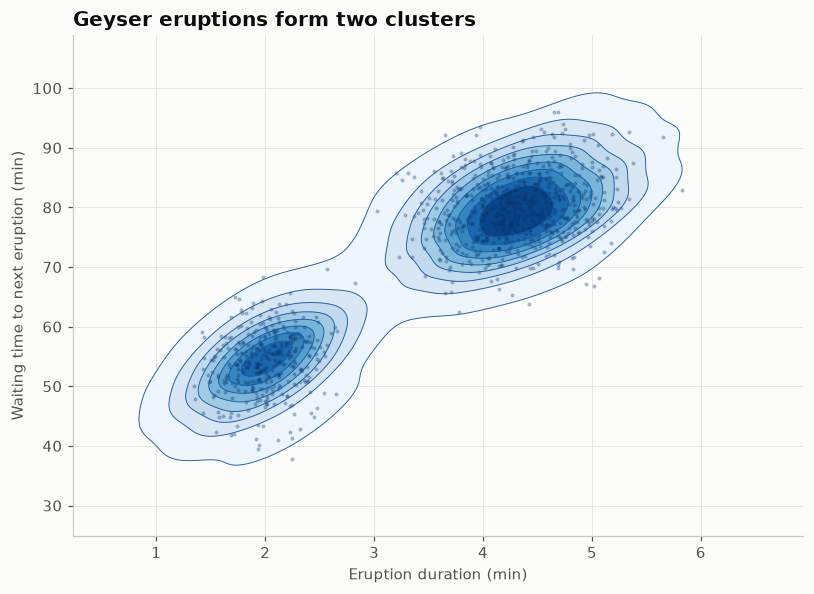

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.kdeplot(data=df, x="duration_min", y="waiting_min", fill=True, cmap=SEQ_CMAP,
            levels=10, thresh=0.03, ax=ax)
sns.kdeplot(data=df, x="duration_min", y="waiting_min", color="#1c5cab",
            levels=10, thresh=0.03, linewidths=0.6, ax=ax)
ax.scatter(df["duration_min"], df["waiting_min"], s=3, color="#0d366b", alpha=0.25)
ax.set_xlabel("Eruption duration (min)")
ax.set_ylabel("Waiting time to next eruption (min)")
ax.set_title("Geyser eruptions form two clusters")
fig.tight_layout()
plt.show()

## How to read it

Darker bands mark higher density, like peaks on a map. Two peaks show two eruption types: short eruptions followed by short waits, and long eruptions followed by long waits.

---
Standalone script: [`density_contour_2d.py`](density_contour_2d.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)